# Use Case 3 — Statistical Insights & Pattern Detection

**Objective:** use numerical and visual analysis to find deeper patterns:
1. crime intensity by hour of day
2. community-area statistics with NumPy and outlier detection (box plot + IQR)
3. correlation between numeric features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()
df = pd.read_pickle(cu.CLEAN_CRIME_FILE)
community = pd.read_pickle(cu.OUTPUT_DIR / "community_lookup.pkl")
print(f"{len(df):,} crimes loaded")

498 crimes loaded


## 1. Crime intensity by time (hour of day)
`df['hour'] = df['date'].dt.hour` was created in notebook 01. `groupby('hour').size()` counts
crimes in each of the 24 hours. `reindex(range(24))` guarantees all hours appear even if one has 0.

⚠ Every crime timestamp is 00:00 — the source 'date' column has dates only (e.g. 5/3/2016).
  df['hour'] = df['date'].dt.hour therefore returns 0 for all rows, and the chart below shows
  a single spike at midnight. That spike is a DATA LIMITATION, not a real crime pattern.


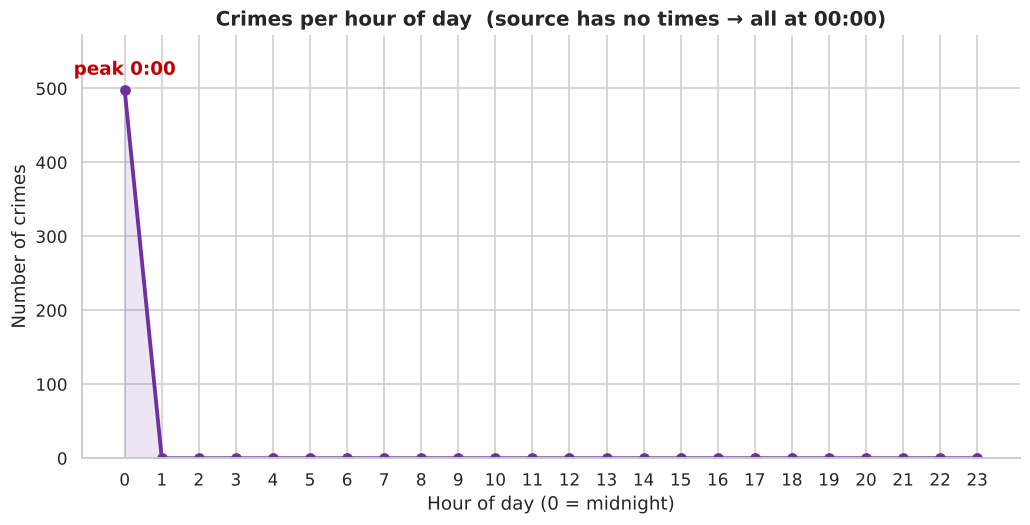

In [2]:
crimes_by_hour = df.groupby("hour").size().reindex(range(24), fill_value=0)

# Check first: does the data actually contain times? If every timestamp is 00:00, the dates were
# recorded without a time of day and "hour" carries no information.
HAS_TIME = (df["date"].dt.time != pd.Timestamp(0).time()).any()
if not HAS_TIME:
    print("⚠ Every crime timestamp is 00:00 — the source 'date' column has dates only (e.g. 5/3/2016).")
    print("  df['hour'] = df['date'].dt.hour therefore returns 0 for all rows, and the chart below shows")
    print("  a single spike at midnight. That spike is a DATA LIMITATION, not a real crime pattern.")

fig, ax = plt.subplots()
ax.plot(crimes_by_hour.index, crimes_by_hour.values, marker="o", linewidth=2.5, color="#7030a0")
ax.fill_between(crimes_by_hour.index, crimes_by_hour.values, alpha=.12, color="#7030a0")
peak, low = crimes_by_hour.idxmax(), crimes_by_hour.idxmin()
ax.annotate(f"peak {peak}:00", (peak, crimes_by_hour[peak]), xytext=(0, 10),
            textcoords="offset points", ha="center", color="#c00000", fontweight="bold")
if HAS_TIME:
    ax.annotate(f"low {low}:00", (low, crimes_by_hour[low]), xytext=(0, -18),
                textcoords="offset points", ha="center", color="#1f4e79", fontweight="bold")
ax.set(title="Crimes per hour of day" + ("" if HAS_TIME else "  (source has no times → all at 00:00)"), xlabel="Hour of day (0 = midnight)", ylabel="Number of crimes")
ax.set_xticks(range(24))
ax.set_ylim(0, crimes_by_hour.max() * 1.15)
cu.save_fig(fig, "uc3_01_crimes_per_hour")
plt.show()

In [3]:
if not HAS_TIME:
    print("Time-of-day bands and the per-type hourly profile are skipped: they need real times.")
    print("With timestamped data, Chicago crime typically dips around 5–6 am and rises through the "
          "afternoon and evening.")
else:
  bands = pd.cut(df["hour"], bins=[-1, 5, 11, 17, 23],
                 labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
  band_share = bands.value_counts(normalize=True).mul(100).round(1).sort_index()
  display(band_share.to_frame("% of crimes").T)
  print(f"Peak hour: {peak}:00 ({crimes_by_hour[peak]:,}) | Quietest: {low}:00 ({crimes_by_hour[low]:,})")
  print(f"The peak hour has {crimes_by_hour[peak] / crimes_by_hour[low]:.1f}x the crimes of the quietest hour.")

  # **Bonus:** does the hourly pattern differ by crime type? A normalised heatmap (each row sums to
  # 100 %) compares *shapes*, not volumes.
  top6 = df["primary_type"].value_counts().head(6).index
  shape = (pd.crosstab(df.loc[df["primary_type"].isin(top6), "primary_type"],
                       df.loc[df["primary_type"].isin(top6), "hour"], normalize="index") * 100)
  fig, ax = plt.subplots(figsize=(13, 4))
  sns.heatmap(shape, cmap="mako_r", ax=ax, cbar_kws={"label": "% of that crime type"})
  ax.set(title="Hourly profile of the top 6 crime types", xlabel="Hour of day", ylabel="")
  cu.save_fig(fig, "uc3_02_hourly_profile_by_type")
  plt.show()

Time-of-day bands and the per-type hourly profile are skipped: they need real times.
With timestamped data, Chicago crime typically dips around 5–6 am and rises through the afternoon and evening.


## 2. Community area clusters using NumPy

First we build one number per community area: its **crime count**. Then NumPy gives the
summary statistics. (`np.mean` of the 77 counts = the average crimes per community area.)

In [4]:
counts = (df["community_code"].dropna().astype(int).value_counts()
            .reindex(community["community_code"].astype(int), fill_value=0))
names = community.set_index(community["community_code"].astype(int))["community_name"].str.title()

arr = counts.to_numpy()                       # plain NumPy array of 77 counts
stats = {
    "areas": arr.size,
    "mean": np.mean(arr),
    "median": np.median(arr),
    "std": np.std(arr, ddof=1),               # ddof=1 -> sample standard deviation
    "min": np.min(arr),
    "max": np.max(arr),
    "Q1 (25th pct)": np.percentile(arr, 25),
    "Q3 (75th pct)": np.percentile(arr, 75),
}
display(pd.Series(stats).round(1).to_frame("value").T)
print(f"Mean crime per community area: {stats['mean']:,.1f}")
print(f"Mean > median ({stats['mean']:.0f} > {stats['median']:.0f}) → right-skewed: "
      "a few areas have far more crime than the rest.")

,areas,mean,median,std,min,max,Q1 (25th pct),Q3 (75th pct)
value,77.0,6.5,5.0,5.9,0.0,34.0,2.0,9.0


Mean crime per community area: 6.5
Mean > median (6 > 5) → right-skewed: a few areas have far more crime than the rest.


**Per-capita view (bonus):** raw counts favour big communities. Dividing by population gives
crimes per 1,000 residents — often a fairer comparison.

In [5]:
pop = community.set_index(community["community_code"].astype(int))["population"].astype(float)
per_1000 = np.round(arr / pop.reindex(counts.index).to_numpy() * 1000, 1)
area_stats = pd.DataFrame({"community_name": names.reindex(counts.index), "crimes": arr,
                           "population": pop.reindex(counts.index).astype("Int64"),
                           "crimes_per_1000": per_1000}, index=counts.index)
display(area_stats.sort_values("crimes_per_1000", ascending=False).head(5))

,community_name,crimes,population,crimes_per_1000
community_code,,,,
37,Fuller Park,3,2221,1.4
26,West Garfield Park,12,15619,0.8
45,Avalon Park,7,9447,0.7
68,Englewood,16,21411,0.7
27,East Garfield Park,12,20526,0.6


### Outliers: box plot, then the IQR method

**Interquartile range (IQR)** = Q3 − Q1 (the spread of the middle 50 %).
A value is an **outlier** if it lies outside the *fences*:

* lower fence = Q1 − 1.5 × IQR
* upper fence = Q3 + 1.5 × IQR

This is exactly the rule a box plot uses to draw its whiskers and dots, so the box plot *shows*
the outliers and the IQR calculation *lists* them.

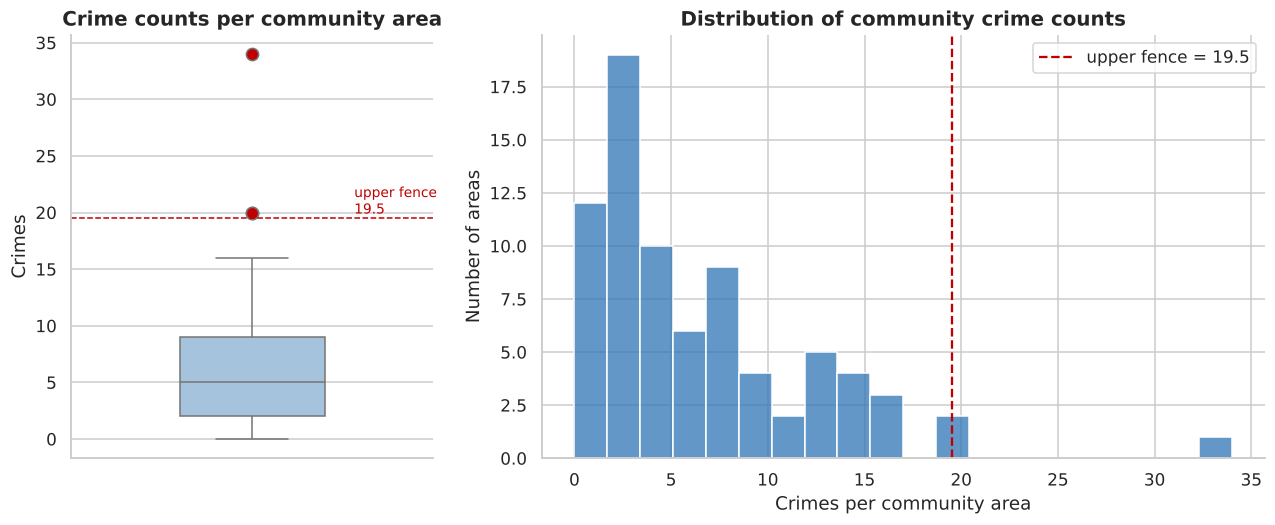

Q1 = 2.0  Q3 = 9.0  IQR = 7.0
Fences: lower = -8.5, upper = 19.5  → an area is an outlier if crimes > 19.5


In [6]:
q1, q3 = np.percentile(arr, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})
sns.boxplot(y=arr, ax=ax1, color="#9dc3e6", width=.4,
            flierprops=dict(marker="o", markerfacecolor="#c00000", markersize=8))
ax1.axhline(upper, color="#c00000", linestyle="--", linewidth=1)
ax1.text(0.27, upper, f" upper fence\n {upper:,.1f}", color="#c00000", va="bottom", fontsize=9)
ax1.set(title="Crime counts per community area", ylabel="Crimes")

sns.histplot(arr, bins=20, ax=ax2, color="#2e75b6")
ax2.axvline(upper, color="#c00000", linestyle="--", label=f"upper fence = {upper:,.1f}")
ax2.set(title="Distribution of community crime counts", xlabel="Crimes per community area",
        ylabel="Number of areas")
ax2.legend()
cu.save_fig(fig, "uc3_03_community_boxplot")
plt.show()

print(f"Q1 = {q1:,.1f}  Q3 = {q3:,.1f}  IQR = {iqr:,.1f}")
print(f"Fences: lower = {lower:,.1f}, upper = {upper:,.1f}  → an area is an outlier if crimes > {upper:,.1f}")

In [7]:
is_outlier = (arr < lower) | (arr > upper)
outliers = (area_stats[is_outlier]
              .assign(type=np.where(arr[is_outlier] > upper, "HIGH", "LOW"),
                      x_times_median=lambda d: (d["crimes"] / np.median(arr)).round(1))
              .sort_values("crimes", ascending=False))
print(f"{is_outlier.sum()} extreme outlier community area(s):")
display(outliers)
if lower < 0:
    print("Note: the lower fence is negative, so low outliers are impossible here — "
          "only unusually HIGH-crime areas can be flagged.")

3 extreme outlier community area(s):


,community_name,crimes,population,crimes_per_1000,type,x_times_median
community_code,,,,,,
25,Austin,34,98882,0.3,HIGH,6.8
8,Near North Side,20,104712,0.2,HIGH,4.0
23,Humboldt Park,20,55598,0.4,HIGH,4.0


Note: the lower fence is negative, so low outliers are impossible here — only unusually HIGH-crime areas can be flagged.


## 3. Crime cross-correlation

`.corr()` computes the **Pearson correlation** (−1 … +1) between every pair of numeric columns.
Booleans (`arrest`, `domestic`) are converted to 0/1 so they can be included, and day of week to
a number (Monday = 0). Reading it:
* ≈ 0 → no linear relationship
* ±0.3 → weak · ±0.5 → moderate · ±0.7+ → strong

Remember: correlation is **not** causation, and codes like `district_code` are labels — a
correlation between two labels only reflects how the numbering was assigned geographically.

Dropped constant column(s) (correlation undefined): ['hour']


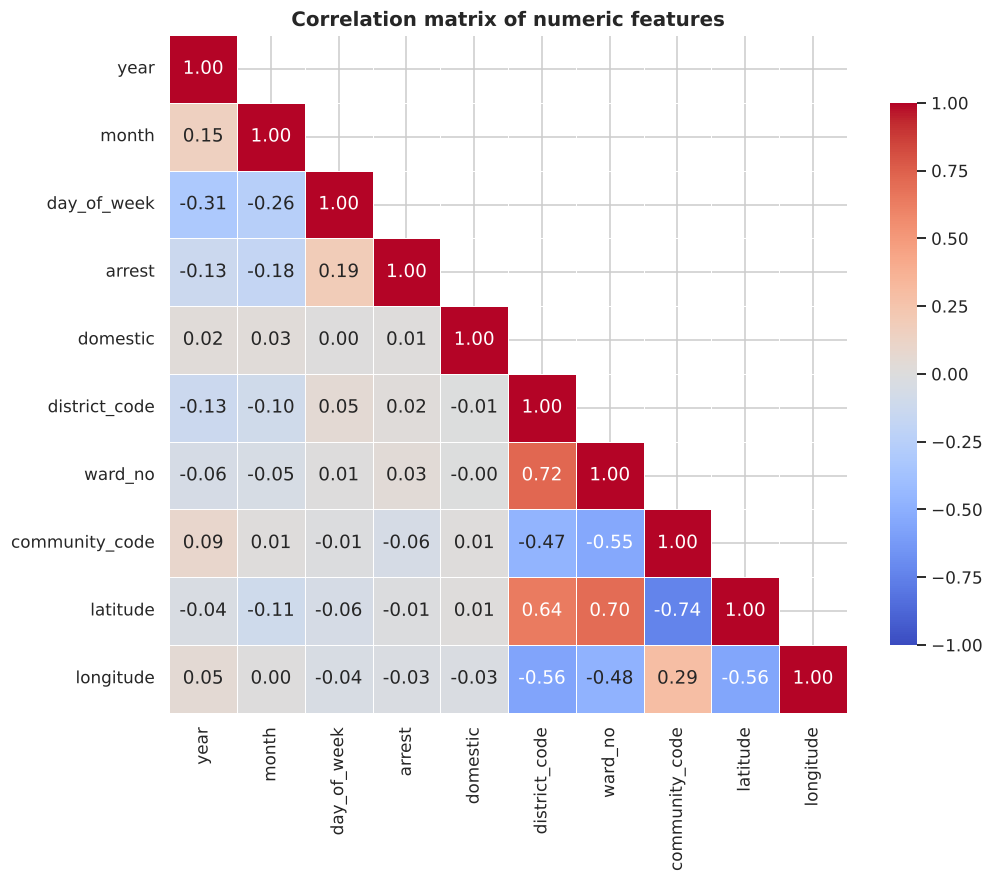

In [8]:
num = pd.DataFrame({
    "year": df["year"], "month": df["month"], "hour": df["hour"],
    "day_of_week": df["date"].dt.dayofweek,
    "arrest": df["arrest"].astype(int), "domestic": df["domestic"].astype(int),
    "district_code": df["district_code"].astype(float),
    "ward_no": df["ward_no"].astype(float),
    "community_code": df["community_code"].astype(float),
    "latitude": df["latitude"], "longitude": df["longitude"],
})
# a column with a single value (e.g. hour = 0 everywhere) has zero variance -> correlation is undefined
constant = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
if constant:
    print(f"Dropped constant column(s) (correlation undefined): {constant}")
num = num.drop(columns=constant)
corr = num.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            center=0, linewidths=.5, square=True, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix of numeric features")
cu.save_fig(fig, "uc3_04_correlation_heatmap")
plt.show()

In [9]:
pairs = (corr.where(~np.tril(np.ones_like(corr, dtype=bool)))   # keep each pair once
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:")
display(pairs.sort_values("abs_r", ascending=False).head(6).round(3))
print(f"Arrest vs year: r = {corr.loc['arrest', 'year']:.3f} (|r| < 0.1 → no meaningful relationship)"
      if abs(corr.loc['arrest', 'year']) < 0.1 else f"Arrest vs year: r = {corr.loc['arrest', 'year']:.3f}")
print("Note: pairs of location codes (district/ward/community/lat/long) correlate because they all "
      "describe WHERE in the city a crime happened — that's geography, not a crime insight.")
print(f"Arrest vs domestic: r = {corr.loc['arrest', 'domestic']:.3f}")

Strongest relationships:


,feature_1,feature_2,r,abs_r
78,community_code,latitude,-0.735,0.735
56,district_code,ward_no,0.721,0.721
68,ward_no,latitude,0.697,0.697
58,district_code,latitude,0.638,0.638
59,district_code,longitude,-0.564,0.564
89,latitude,longitude,-0.562,0.562


Arrest vs year: r = -0.131
Note: pairs of location codes (district/ward/community/lat/long) correlate because they all describe WHERE in the city a crime happened — that's geography, not a crime insight.
Arrest vs domestic: r = 0.014
